In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
import statsmodels.api as sm
from statsmodels.stats.proportion import proportions_ztest, proportion_confint

pd.set_option('display.max_columns', None)

print("Libraries imported successfully!")

Libraries imported successfully!


In [2]:
ab_data = pd.read_csv("ab_data.csv")

countries = pd.read_csv("countries.csv")

print("A/B Test Dataset Shape:", ab_data.shape)
print("Countries Dataset Shape:", countries.shape)

print("\nA/B Test Columns:")
print(ab_data.columns.tolist())

print("\nCountries Columns:")
print(countries.columns.tolist())

A/B Test Dataset Shape: (294478, 5)
Countries Dataset Shape: (290584, 2)

A/B Test Columns:
['user_id', 'timestamp', 'group', 'landing_page', 'converted']

Countries Columns:
['user_id', 'country']


In [3]:
print(ab_data.head())

   user_id                   timestamp      group landing_page  converted
0   851104  2017-01-21 22:11:48.556739    control     old_page          0
1   804228  2017-01-12 08:01:45.159739    control     old_page          0
2   661590  2017-01-11 16:55:06.154213  treatment     new_page          0
3   853541  2017-01-08 18:28:03.143765  treatment     new_page          0
4   864975  2017-01-21 01:52:26.210827    control     old_page          1


In [4]:
ab_data.info()

<class 'pandas.DataFrame'>
RangeIndex: 294478 entries, 0 to 294477
Data columns (total 5 columns):
 #   Column        Non-Null Count   Dtype
---  ------        --------------   -----
 0   user_id       294478 non-null  int64
 1   timestamp     294478 non-null  str  
 2   group         294478 non-null  str  
 3   landing_page  294478 non-null  str  
 4   converted     294478 non-null  int64
dtypes: int64(2), str(3)
memory usage: 11.2 MB


In [5]:
ab_data.describe()

,user_id,converted
count,294478.000000,294478.000000
mean,787974.124733,0.119659
std,91210.823776,0.324563
min,630000.000000,0.000000
25%,709032.250000,0.000000
50%,787933.500000,0.000000
75%,866911.750000,0.000000
max,945999.000000,1.000000


In [6]:
print("Missing values:")
print(ab_data.isnull().sum())

Missing values:
user_id         0
timestamp       0
group           0
landing_page    0
converted       0
dtype: int64


In [7]:
print("Groups:")
print(ab_data['group'].unique())

print("\nLanding Pages:")
print(ab_data['landing_page'].unique())

print("\nConversion Values:")
print(ab_data['converted'].unique())

Groups:
<StringArray>
['control', 'treatment']
Length: 2, dtype: str

Landing Pages:
<StringArray>
['old_page', 'new_page']
Length: 2, dtype: str

Conversion Values:
[0 1]


In [8]:
print(ab_data['group'].value_counts())

group
treatment    147276
control      147202
Name: count, dtype: int64


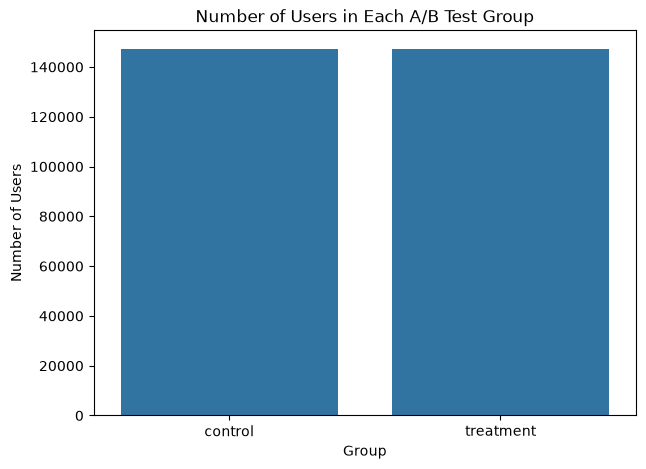

In [9]:
plt.figure(figsize=(7,5))

sns.countplot(
    data=ab_data,
    x='group'
)

plt.title("Number of Users in Each A/B Test Group")
plt.xlabel("Group")
plt.ylabel("Number of Users")
plt.show()

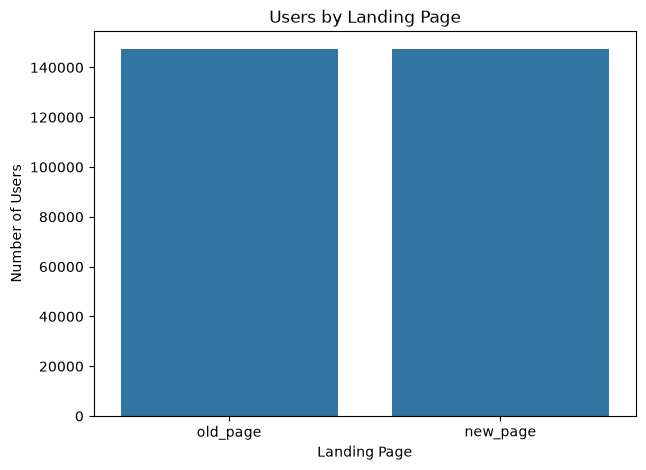

In [10]:
plt.figure(figsize=(7,5))

sns.countplot(
    data=ab_data,
    x='landing_page'
)

plt.title("Users by Landing Page")
plt.xlabel("Landing Page")
plt.ylabel("Number of Users")
plt.show()

In [11]:
clean_data = ab_data[
    ((ab_data['group'] == 'control') & 
     (ab_data['landing_page'] == 'old_page')) |
    
    ((ab_data['group'] == 'treatment') & 
     (ab_data['landing_page'] == 'new_page'))
].copy()

print("Shape after removing mismatched records:")
print(clean_data.shape)

Shape after removing mismatched records:
(290585, 5)


In [12]:
duplicates = clean_data['user_id'].duplicated().sum()

print("Number of duplicate user records:", duplicates)

Number of duplicate user records: 1


In [13]:
clean_data = clean_data.drop_duplicates(
    subset='user_id',
    keep='first'
)

print("Shape after removing duplicates:")
print(clean_data.shape)

Shape after removing duplicates:
(290584, 5)


In [14]:
data = pd.merge(
    clean_data,
    countries,
    on='user_id',
    how='inner'
)

print("Final Dataset Shape:")
print(data.shape)

print("\nFirst 5 rows:")
print(data.head())

Final Dataset Shape:
(290584, 6)

First 5 rows:
   user_id                   timestamp      group landing_page  converted  \
0   851104  2017-01-21 22:11:48.556739    control     old_page          0   
1   804228  2017-01-12 08:01:45.159739    control     old_page          0   
2   661590  2017-01-11 16:55:06.154213  treatment     new_page          0   
3   853541  2017-01-08 18:28:03.143765  treatment     new_page          0   
4   864975  2017-01-21 01:52:26.210827    control     old_page          1   

  country  
0      US  
1      US  
2      US  
3      US  
4      US  


In [15]:
print(data.info())

<class 'pandas.DataFrame'>
RangeIndex: 290584 entries, 0 to 290583
Data columns (total 6 columns):
 #   Column        Non-Null Count   Dtype
---  ------        --------------   -----
 0   user_id       290584 non-null  int64
 1   timestamp     290584 non-null  str  
 2   group         290584 non-null  str  
 3   landing_page  290584 non-null  str  
 4   converted     290584 non-null  int64
 5   country       290584 non-null  str  
dtypes: int64(2), str(4)
memory usage: 13.3 MB
None


In [16]:
print("\nMissing values:")
print(data.isnull().sum())


Missing values:
user_id         0
timestamp       0
group           0
landing_page    0
converted       0
country         0
dtype: int64


In [17]:
print("\nFinal group distribution:")
print(data['group'].value_counts())


Final group distribution:
group
treatment    145310
control      145274
Name: count, dtype: int64


In [18]:
group_summary = data.groupby('group')['converted'].agg(
    ['count', 'sum', 'mean']
)

group_summary

,count,sum,mean
group,,,
control,145274,17489,0.120386
treatment,145310,17264,0.118808


In [19]:
group_summary.columns = [
    'Users',
    'Conversions',
    'Conversion_Rate'
]

group_summary['Conversion_Rate_Percentage'] = (
    group_summary['Conversion_Rate'] * 100
)

group_summary

,Users,Conversions,Conversion_Rate,Conversion_Rate_Percentage
group,,,,
control,145274,17489,0.120386,12.038630
treatment,145310,17264,0.118808,11.880807


In [20]:
control_rate = data[
    data['group'] == 'control'
]['converted'].mean()

treatment_rate = data[
    data['group'] == 'treatment'
]['converted'].mean()

difference = treatment_rate - control_rate

print("Control Conversion Rate:",
      round(control_rate * 100, 3), "%")

print("Treatment Conversion Rate:",
      round(treatment_rate * 100, 3), "%")

print("Difference:",
      round(difference * 100, 3), "percentage points")

Control Conversion Rate: 12.039 %
Treatment Conversion Rate: 11.881 %
Difference: -0.158 percentage points


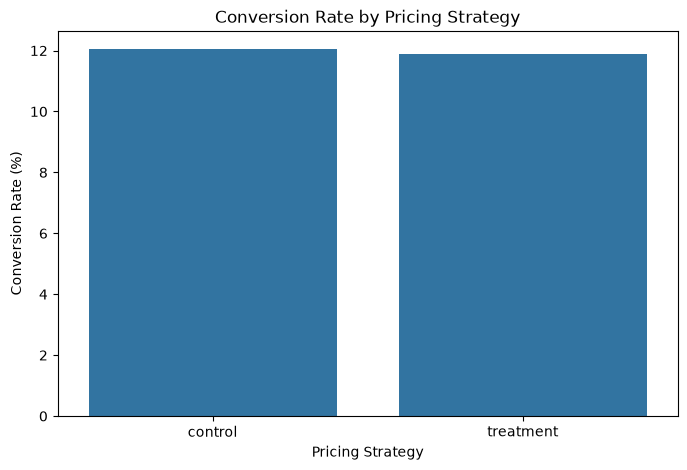

In [21]:
conversion_rates = data.groupby('group')['converted'].mean() * 100

plt.figure(figsize=(8,5))

sns.barplot(
    x=conversion_rates.index,
    y=conversion_rates.values
)

plt.title("Conversion Rate by Pricing Strategy")
plt.xlabel("Pricing Strategy")
plt.ylabel("Conversion Rate (%)")

plt.show()

In [22]:
alpha = 0.05

In [23]:
control = data[
    data['group'] == 'control'
]['converted']

treatment = data[
    data['group'] == 'treatment'
]['converted']

t_stat, p_value = stats.ttest_ind(
    treatment,
    control,
    equal_var=False
)

print("T-statistic:", t_stat)
print("P-value:", p_value)
print("Significance Level:", alpha)

if p_value < alpha:
    print("Reject H0")
    print("There is a statistically significant difference.")
else:
    print("Fail to Reject H0")
    print("There is no statistically significant difference.")

T-statistic: -1.310922637465592
P-value: 0.18988493791578315
Significance Level: 0.05
Fail to Reject H0
There is no statistically significant difference.


In [24]:
contingency_table = pd.crosstab(
    data['group'],
    data['converted']
)

print(contingency_table)

converted       0      1
group                   
control    127785  17489
treatment  128046  17264


In [25]:
chi2, p_value_chi, dof, expected = stats.chi2_contingency(
    contingency_table
)

print("Chi-square statistic:", chi2)
print("Degrees of freedom:", dof)
print("P-value:", p_value_chi)

if p_value_chi < alpha:
    print("Reject H0")
    print("Group and conversion are significantly related.")
else:
    print("Fail to Reject H0")
    print("Group and conversion are statistically independent.")

Chi-square statistic: 1.7035660051885058
Degrees of freedom: 1
P-value: 0.19182228096235662
Fail to Reject H0
Group and conversion are statistically independent.


In [26]:
country_summary = data.groupby('country')['converted'].agg(
    ['count', 'sum', 'mean']
)

country_summary.columns = [
    'Users',
    'Conversions',
    'Conversion_Rate'
]

country_summary['Conversion_Rate_Percentage'] = (
    country_summary['Conversion_Rate'] * 100
)

country_summary

,Users,Conversions,Conversion_Rate,Conversion_Rate_Percentage
country,,,,
CA,14499,1672,0.115318,11.531830
UK,72466,8739,0.120594,12.059449
US,203619,24342,0.119547,11.954680


In [27]:
country_groups = [
    group['converted'].values
    for country, group in data.groupby('country')
]

f_stat, p_value_anova = stats.f_oneway(
    *country_groups
)

print("F-statistic:", f_stat)
print("P-value:", p_value_anova)

if p_value_anova < alpha:
    print("Reject H0")
    print("At least one country has a significantly different conversion rate.")
else:
    print("Fail to Reject H0")
    print("There is no statistically significant difference among countries.")

F-statistic: 1.605286395923647
P-value: 0.2008338102216084
Fail to Reject H0
There is no statistically significant difference among countries.


In [28]:
data['country_strategy'] = (
    data['country'] + "_" + data['group']
)

print(
    data['country_strategy'].value_counts()
)

country_strategy
US_treatment    101903
US_control      101716
UK_control       36360
UK_treatment     36106
CA_treatment      7301
CA_control        7198
Name: count, dtype: int64


In [29]:
country_strategy_groups = [
    group['converted'].values
    for name, group
    in data.groupby('country_strategy')
]

f_stat_cs, p_value_cs = stats.f_oneway(
    *country_strategy_groups
)

print("F-statistic:", f_stat_cs)
print("P-value:", p_value_cs)

F-statistic: 1.4664379009534323
P-value: 0.19708747683579728


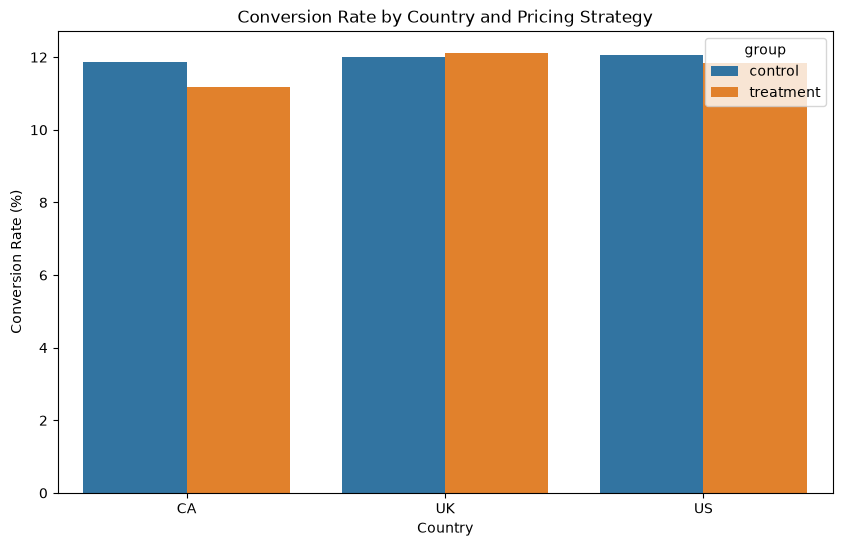

In [30]:
country_strategy_summary = (
    data.groupby(['country', 'group'])['converted']
    .mean()
    .reset_index()
)

country_strategy_summary['converted'] *= 100

plt.figure(figsize=(10,6))

sns.barplot(
    data=country_strategy_summary,
    x='country',
    y='converted',
    hue='group'
)

plt.title("Conversion Rate by Country and Pricing Strategy")
plt.xlabel("Country")
plt.ylabel("Conversion Rate (%)")

plt.show()

In [31]:
for group_name in ['control', 'treatment']:
    
    conversions = data[
        data['group'] == group_name
    ]['converted'].sum()
    
    total = data[
        data['group'] == group_name
    ].shape[0]
    
    ci_low, ci_high = proportion_confint(
        conversions,
        total,
        alpha=0.05,
        method='wilson'
    )
    
    print(group_name)
    print("Conversion Rate:", conversions / total)
    print("95% CI:", ci_low, ci_high)
    print()

control
Conversion Rate: 0.1203863045004612
95% CI: 0.11872297704421185 0.1220697075630713

treatment
Conversion Rate: 0.11880806551510564
95% CI: 0.11715449706961521 0.12048178803682728



In [32]:
from statsmodels.stats.proportion import confint_proportions_2indep

control_conversions = data[
    data['group'] == 'control'
]['converted'].sum()

control_total = data[
    data['group'] == 'control'
].shape[0]

treatment_conversions = data[
    data['group'] == 'treatment'
]['converted'].sum()

treatment_total = data[
    data['group'] == 'treatment'
].shape[0]

ci_low, ci_high = confint_proportions_2indep(
    treatment_conversions,
    treatment_total,
    control_conversions,
    control_total,
    method='wald'
)

print("95% CI for treatment - control:")
print(ci_low, ci_high)

95% CI for treatment - control:
-0.003937860245052737 0.0007813822743416238


In [33]:
results = pd.DataFrame({
    'Test': [
        'Welch T-Test',
        'Chi-Square Test',
        'ANOVA - Country',
        'ANOVA - Country + Strategy'
    ],
    
    'Statistic': [
        t_stat,
        chi2,
        f_stat,
        f_stat_cs
    ],
    
    'P_Value': [
        p_value,
        p_value_chi,
        p_value_anova,
        p_value_cs
    ]
})

results['Decision'] = np.where(
    results['P_Value'] < alpha,
    'Reject H0',
    'Fail to Reject H0'
)

results

,Test,Statistic,P_Value,Decision
0,Welch T-Test,-1.310923,0.189885,Fail to Reject H0
1,Chi-Square Test,1.703566,0.191822,Fail to Reject H0
2,ANOVA - Country,1.605286,0.200834,Fail to Reject H0
3,ANOVA - Country + Strategy,1.466438,0.197087,Fail to Reject H0
